In [1]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# 1. Temizlenmiş veriyi 1. notebook'tan hazır DataFrame olarak varsayıyoruz
# (Önceki adımda oluşturduğumuz df_final üzerinden işlem yapıyoruz)

# Girdi (X) ve Hedef Değişkeni (y) Ayırma
X = df_final.drop(columns=['churn_flag'])
y = df_final['churn_flag']

# 2. Veriyi %80 Eğitim, %20 Test Olarak Bölme
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Eğitim Seti Boyutu: {X_train.shape}")
print(f"Test Seti Boyutu: {X_test.shape}")

# ----------------------------------------------------
# 3. MODELLERİN EĞİTİLMESİ
# ----------------------------------------------------

# A) Logistic Regression (Referans / Baseline Model)
print("\n1. Logistic Regression Eğitiliyor...")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# B) Random Forest Classifier
print("2. Random Forest Eğitiliyor...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# C) XGBoost Classifier (Gelişmiş Model)
print("3. XGBoost Eğitiliyor...")
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

print("\n--- TÜM MODELLER BAŞARIYLA EĞİTİLDİ ---")

NameError: name 'df_final' is not defined

In [2]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score

# 1. Veri Setini Yükle ve Temizle
df = pd.read_csv('E-commerce_Customer_Churn_2026.csv')

# Data Leakage sütunlarını çıkar
leakage_columns = [
    'churn_id', 'customer_id', 'churn_date', 'days_since_churn', 
    'churn_reason', 'churn_category', 'churn_risk_score', 
    'churn_probability', 'predicted_churn', 'churn_risk_category',
    'churn_revenue_impact_usd', 'retention_probability'
]
df_clean = df.drop(columns=leakage_columns)

# Eksik verileri doldur
num_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

cat_cols = df_clean.select_dtypes(include=['object']).columns
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# One-Hot Encoding
features = df_clean.drop(columns=['is_churned', 'churn_flag'])
features_encoded = pd.get_dummies(features, drop_first=True)
df_final = pd.concat([features_encoded, df_clean[['churn_flag']]], axis=1)

# 2. Girdi (X) ve Hedef Değişkeni (y) Ayırma
X = df_final.drop(columns=['churn_flag'])
y = df_final['churn_flag']

# 3. Veriyi Eğitim ve Test Olarak Bölme (%80 Train, %20 Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Eğitim Seti: {X_train.shape}, Test Seti: {X_test.shape}")

# 4. MODELLERİN EĞİTİLMESİ
print("\n1. Logistic Regression Eğitiliyor...")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

print("2. Random Forest Eğitiliyor...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

print("3. XGBoost Eğitiliyor...")
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

# 5. PERFORMANS EVALUATION
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_prob)
    
    print(f"\n================ {name} Performansı ================")
    print(classification_report(y_test, y_pred))
    print(f"ROC-AUC Skoru: {auc:.4f}")
    results.append({"Model": name, "ROC-AUC": auc, "Object": model})

# En başarılı modeli otomatik kaydet
best_model_info = max(results, key=lambda x: x["ROC-AUC"])
print(f"\n🏆 EN BAŞARILI MODEL: {best_model_info['Model']} (ROC-AUC: {best_model_info['ROC-AUC']:.4f})")

joblib.dump(best_model_info["Object"], "best_churn_model.pkl")
joblib.dump(X.columns.tolist(), "model_columns.pkl")

print("\nModel ('best_churn_model.pkl') ve sütun yapısı başarıyla kaydedildi!")

C:\Users\fgulf\AppData\Local\Temp\ipykernel_29248\4293168346.py:27: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_clean.select_dtypes(include=['object']).columns


Eğitim Seti: (40000, 225), Test Seti: (10000, 225)

1. Logistic Regression Eğitiliyor...


c:\Users\fgulf\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


2. Random Forest Eğitiliyor...
3. XGBoost Eğitiliyor...

================ Logistic Regression Performansı ================
              precision    recall  f1-score   support

           0       0.68      0.86      0.76      5869
           1       0.68      0.43      0.52      4131

    accuracy                           0.68     10000
   macro avg       0.68      0.64      0.64     10000
weighted avg       0.68      0.68      0.66     10000

ROC-AUC Skoru: 0.7319

================ Random Forest Performansı ================
              precision    recall  f1-score   support

           0       1.00      0.86      0.92      5869
           1       0.83      0.99      0.91      4131

    accuracy                           0.92     10000
   macro avg       0.91      0.93      0.91     10000
weighted avg       0.93      0.92      0.92     10000

ROC-AUC Skoru: 0.9661

================ XGBoost Performansı ================
              precision    recall  f1-score   support

        

In [3]:
%pip install shap

     ---------------------------------------- 0.0/57.4 kB ? eta -:--:--
     --------------------- ------------------ 30.7/57.4 kB 1.3 MB/s eta 0:00:01
     ---------------------------------------- 57.4/57.4 kB 1.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/499.9 kB ? eta -:--:--
   --------- ------------------------------ 112.6/499.9 kB 3.2 MB/s eta 0:00:01
   ------------- -------------------------- 174.1/499.9 kB 2.1 MB/s eta 0:00:01
   ------------------------------- -------- 389.1/499.9 kB 3.0 MB/s eta 0:00:01
   ---------------------------------------- 499.9/499.9 kB 3.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/80.2 kB ? eta -:--:--
   ---------------------------------------- 80.2/80.2 kB ? eta 0:00:00
   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
    --------------------------------------- 0.6/41.9 MB 19.5 MB/s eta 0:00:03
   - -------------------------------------- 1.2/41.9 MB 15.6 MB/s eta 0:00:03
   - -----

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


c:\Users\fgulf\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


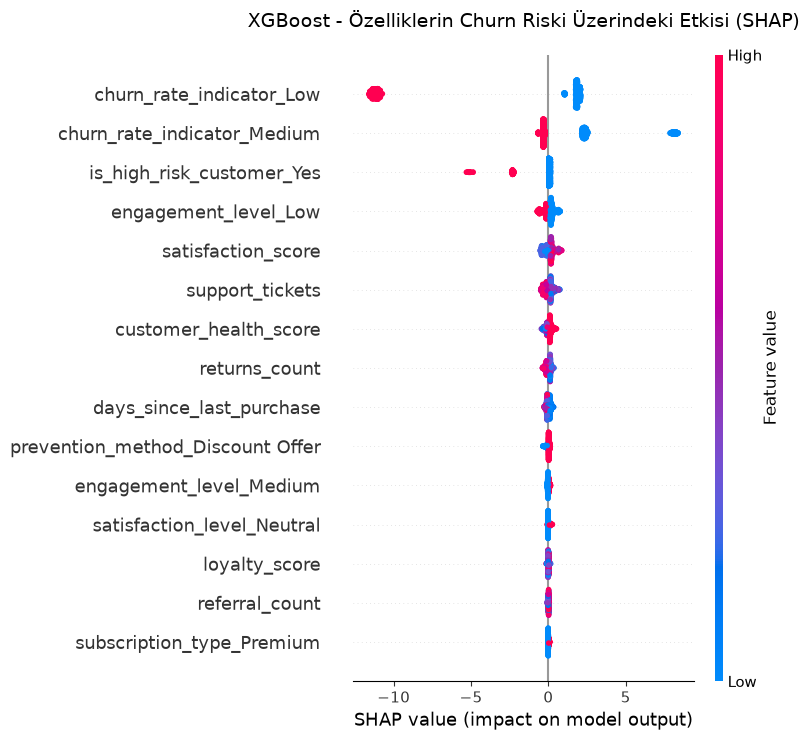

In [4]:
import shap
import matplotlib.pyplot as plt

# 1. XGBoost Modeli İçin SHAP Explainer Oluşturma
explainer = shap.TreeExplainer(best_model_info["Object"])

# Test setinden temsil edici 1000 örnek alarak SHAP değerlerini hesaplayalım
X_test_sample = X_test.sample(1000, random_state=42)
shap_values = explainer(X_test_sample)

# 2. SHAP Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_sample, max_display=15, show=False)
plt.title("XGBoost - Özelliklerin Churn Riski Üzerindeki Etkisi (SHAP)", fontsize=14, pad=20)
plt.tight_layout()
plt.show()